# California Housing - ML Capstone Project
Regression (Linear Regression), Classification (Decision Tree), Clustering (K-Means)

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (mean_squared_error, r2_score, accuracy_score,
                             confusion_matrix, precision_score, recall_score,
                             silhouette_score)

## 1. Data Loading and Inspection

In [2]:
paths = ['housing.csv', 'housing.csv.txt', 'data/housing.csv', '../data/housing.csv']
fname = next(p for p in paths if os.path.exists(p))
df = pd.read_csv(fname)
print(df.shape)
df.info()
print(df.isna().sum())
df.head()

(20640, 10)
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity     

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 2. Exploratory Data Analysis

count     20640.000000
mean     206855.816909
std      115395.615874
min       14999.000000
25%      119600.000000
50%      179700.000000
75%      264725.000000
max      500001.000000
Name: median_house_value, dtype: float64
median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64


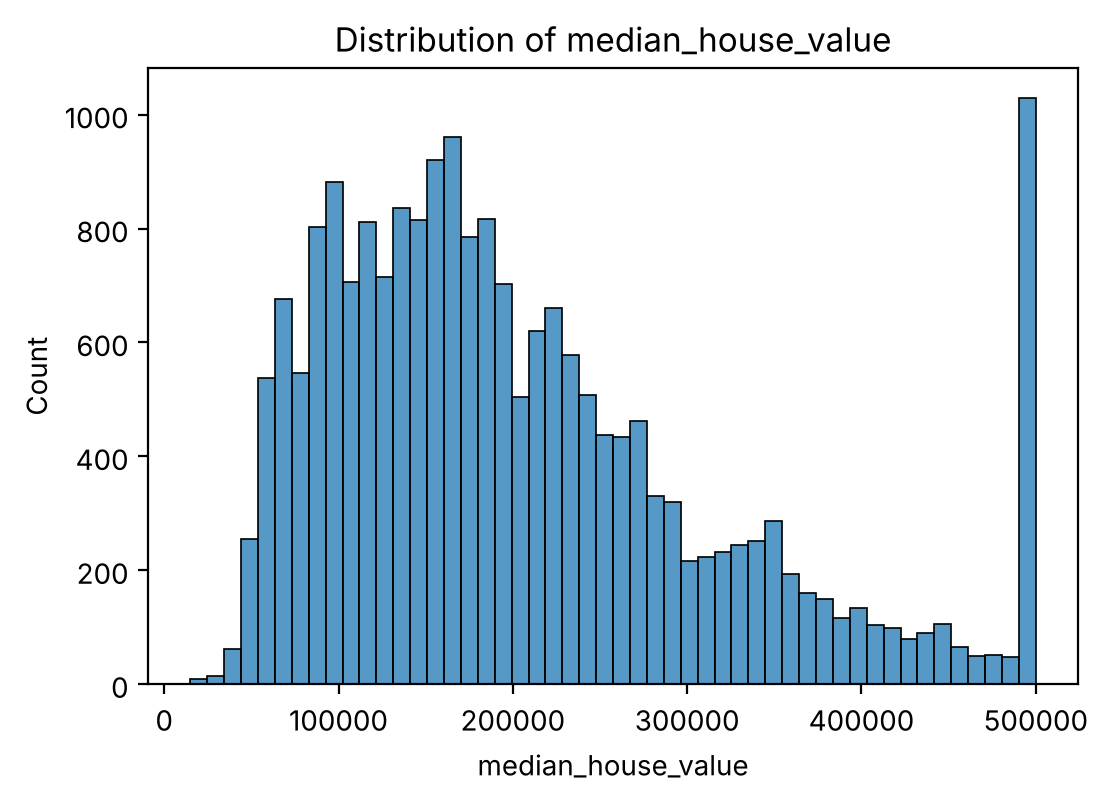

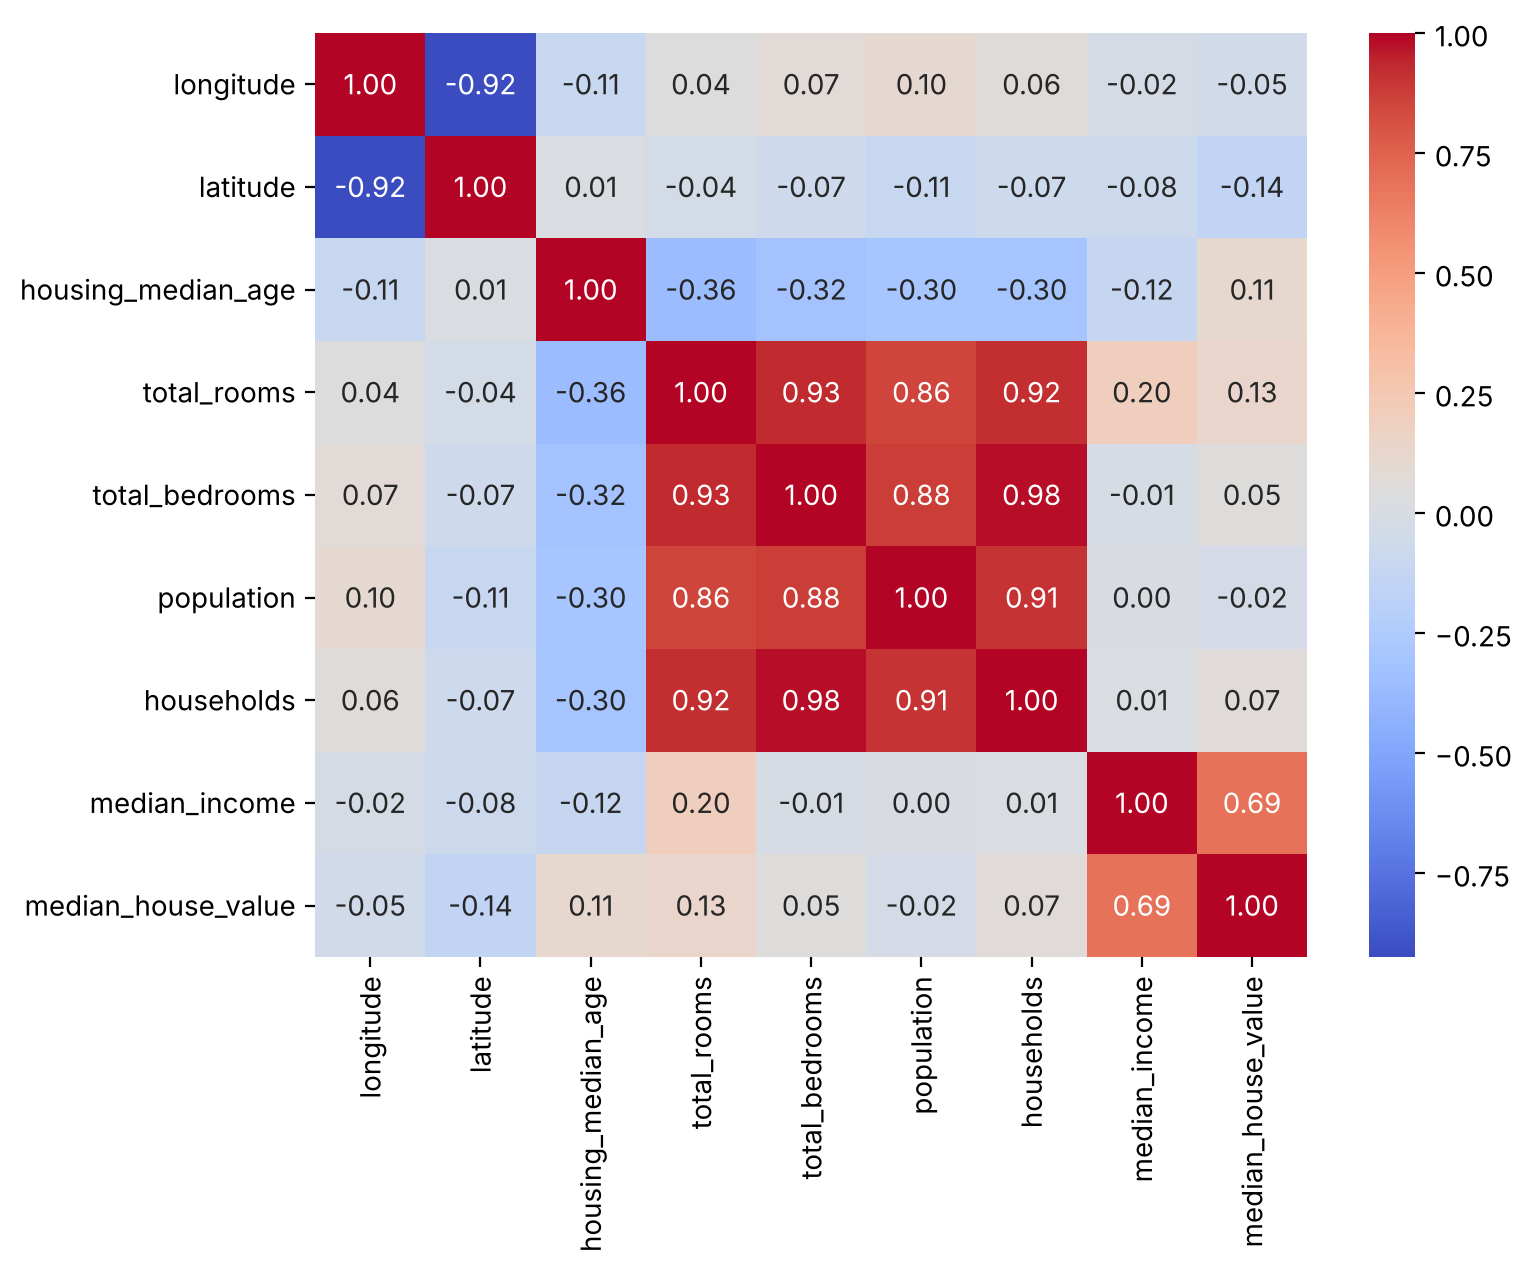

In [3]:
print(df['median_house_value'].describe())

plt.figure(figsize=(6,4))
sns.histplot(df['median_house_value'], bins=50)
plt.title('Distribution of median_house_value')
plt.show()

corr = df.drop(columns='ocean_proximity').corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.show()
print(corr['median_house_value'].sort_values(ascending=False))

## 3. Cleaning and Encoding

In [4]:
df['total_bedrooms'] = df['total_bedrooms'].fillna(df['total_bedrooms'].median())
df = pd.get_dummies(df, columns=['ocean_proximity'], dtype=int)
print(df.shape, 'missing:', df.isna().sum().sum())

(20640, 14) missing: 0


## 4. Regression: Linear Regression

In [5]:
X = df.drop('median_house_value', axis=1)
y = df['median_house_value']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

lr = LinearRegression().fit(X_train_s, y_train)
pred = lr.predict(X_test_s)
mse = mean_squared_error(y_test, pred)
print('MSE :', mse)
print('RMSE:', mse ** 0.5)
print('R2  :', r2_score(y_test, pred))

MSE : 4908476721.156615
RMSE: 70060.52184473518
R2  : 0.6254240620553606


## 5. Classification: Decision Tree

Accuracy : 0.8146802325581395
Precision: 0.8079501915708812
Recall   : 0.8225255972696246
[[1676  401]
 [ 364 1687]]


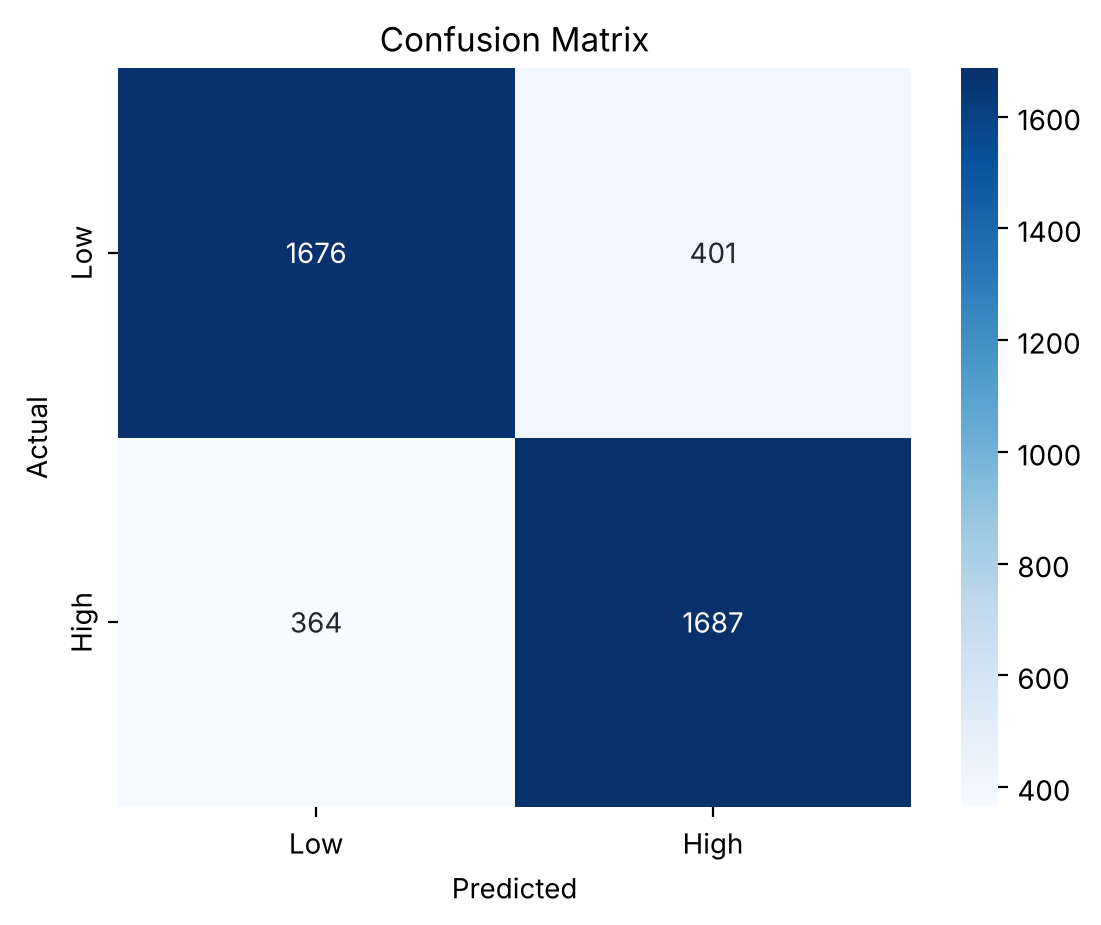

In [6]:
df['high_price'] = (df['median_house_value'] > df['median_house_value'].median()).astype(int)

Xc = df.drop(['median_house_value', 'high_price'], axis=1)
yc = df['high_price']
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.2, random_state=42)

dt = DecisionTreeClassifier(max_depth=5, random_state=42).fit(Xc_tr, yc_tr)
p = dt.predict(Xc_te)

print('Accuracy :', accuracy_score(yc_te, p))
print('Precision:', precision_score(yc_te, p))
print('Recall   :', recall_score(yc_te, p))

cm = confusion_matrix(yc_te, p)
print(cm)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Low', 'High'], yticklabels=['Low', 'High'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

## 6. Clustering: K-Means (Elbow Method)

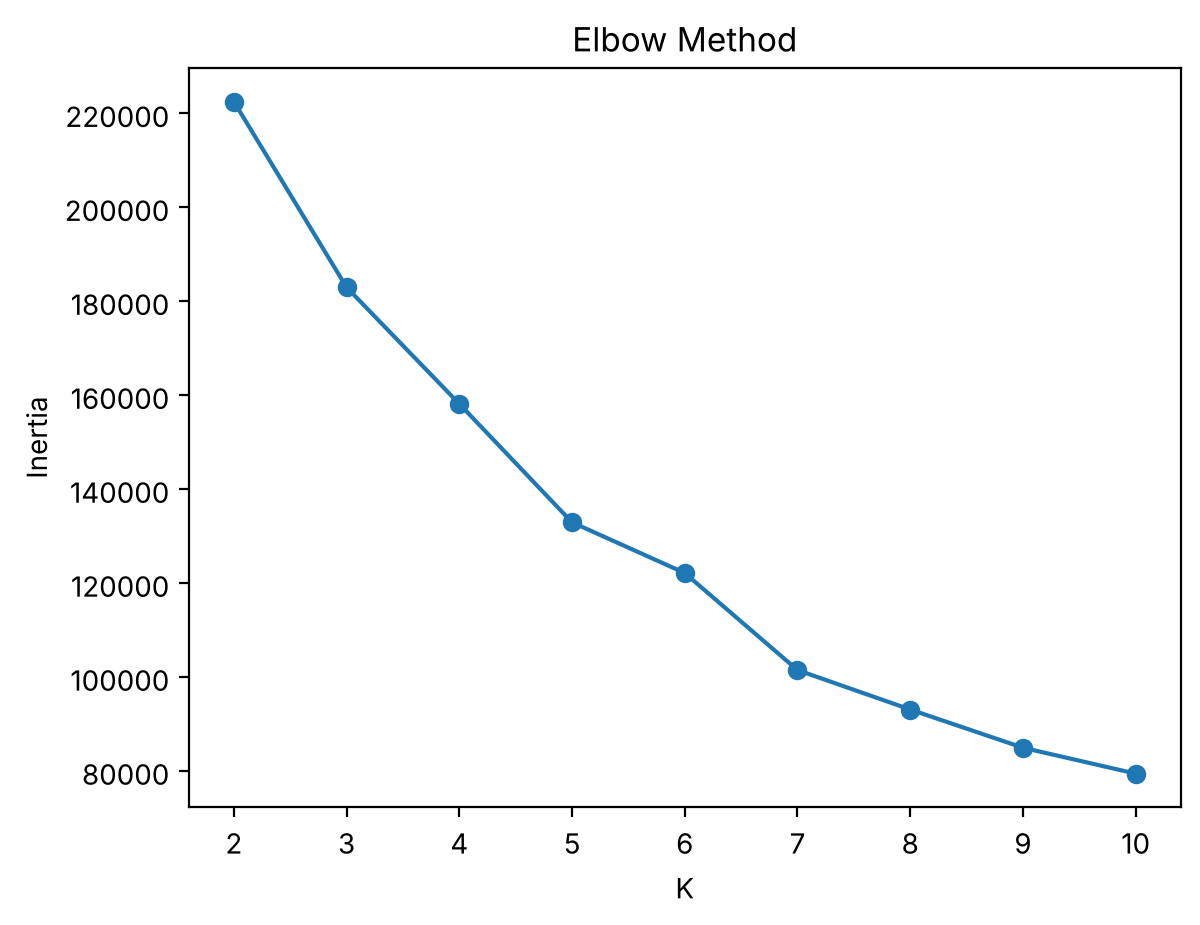

In [7]:
Xk = StandardScaler().fit_transform(Xc)

ks = range(2, 11)
inertias = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xk).inertia_ for k in ks]

plt.plot(ks, inertias, marker='o')
plt.xlabel('K')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

Silhouette: 0.3612099563663257
         median_house_value  median_income
cluster                                   
0             248440.481970       3.977300
1             122823.250827       3.158265
2             239262.964824       4.218604
3             214123.259259       4.217457
4             259225.120433       4.153381


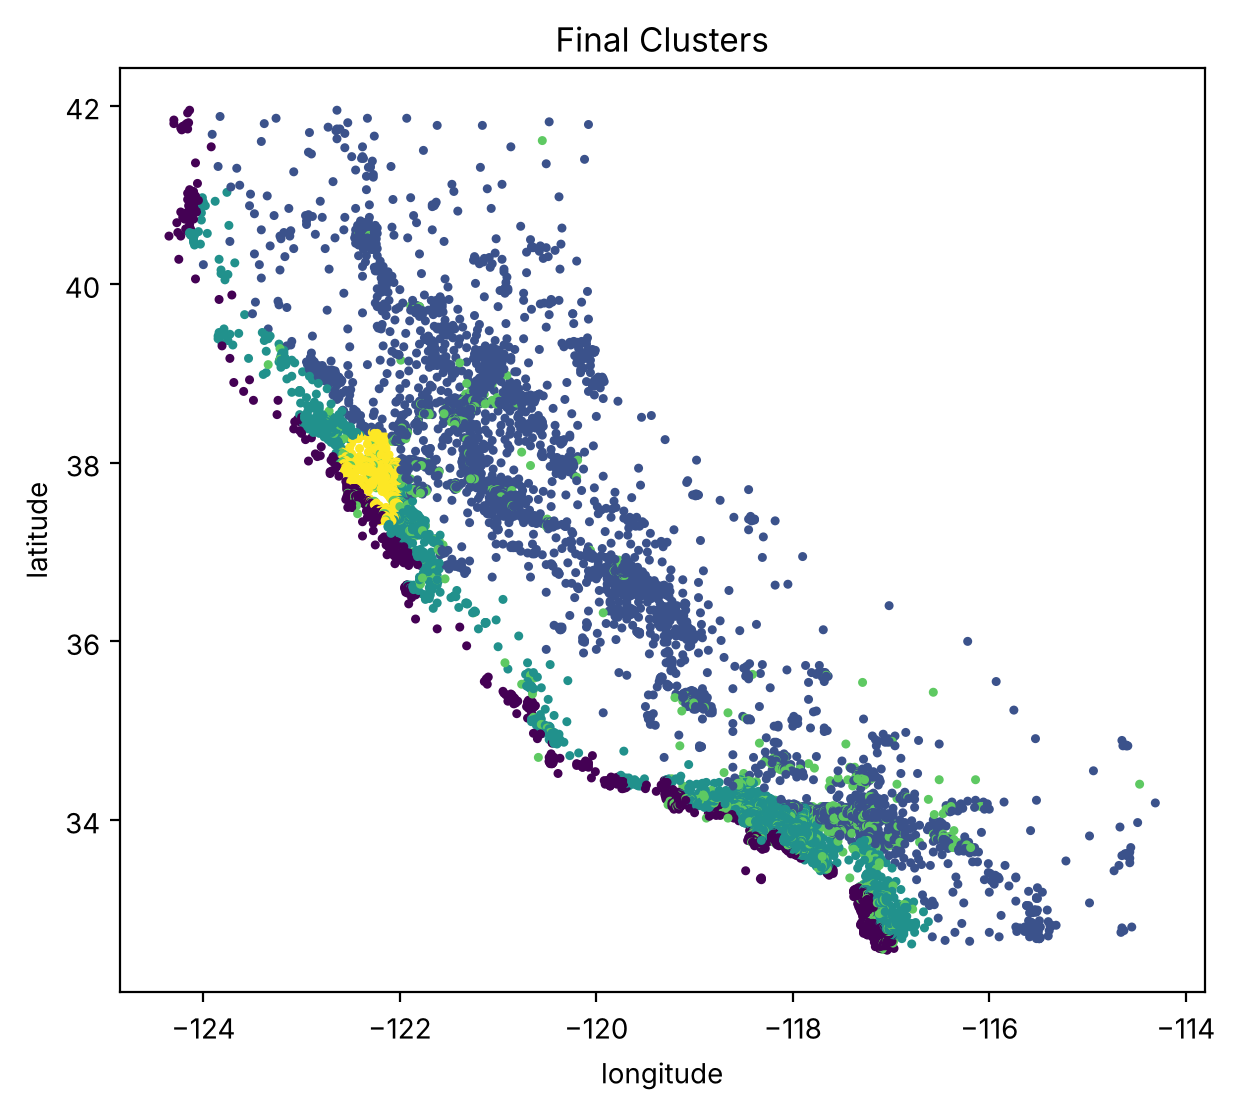

In [8]:
K = 5
km = KMeans(n_clusters=K, random_state=42, n_init=10).fit(Xk)
df['cluster'] = km.labels_

print('Silhouette:', silhouette_score(Xk, km.labels_))

plt.figure(figsize=(7,6))
plt.scatter(df['longitude'], df['latitude'], c=km.labels_, cmap='viridis', s=5)
plt.xlabel('longitude')
plt.ylabel('latitude')
plt.title('Final Clusters')
plt.show()

print(df.groupby('cluster')[['median_house_value', 'median_income']].mean())

## 7. Extra: Random Forest

RF R2: 0.8169411111174801


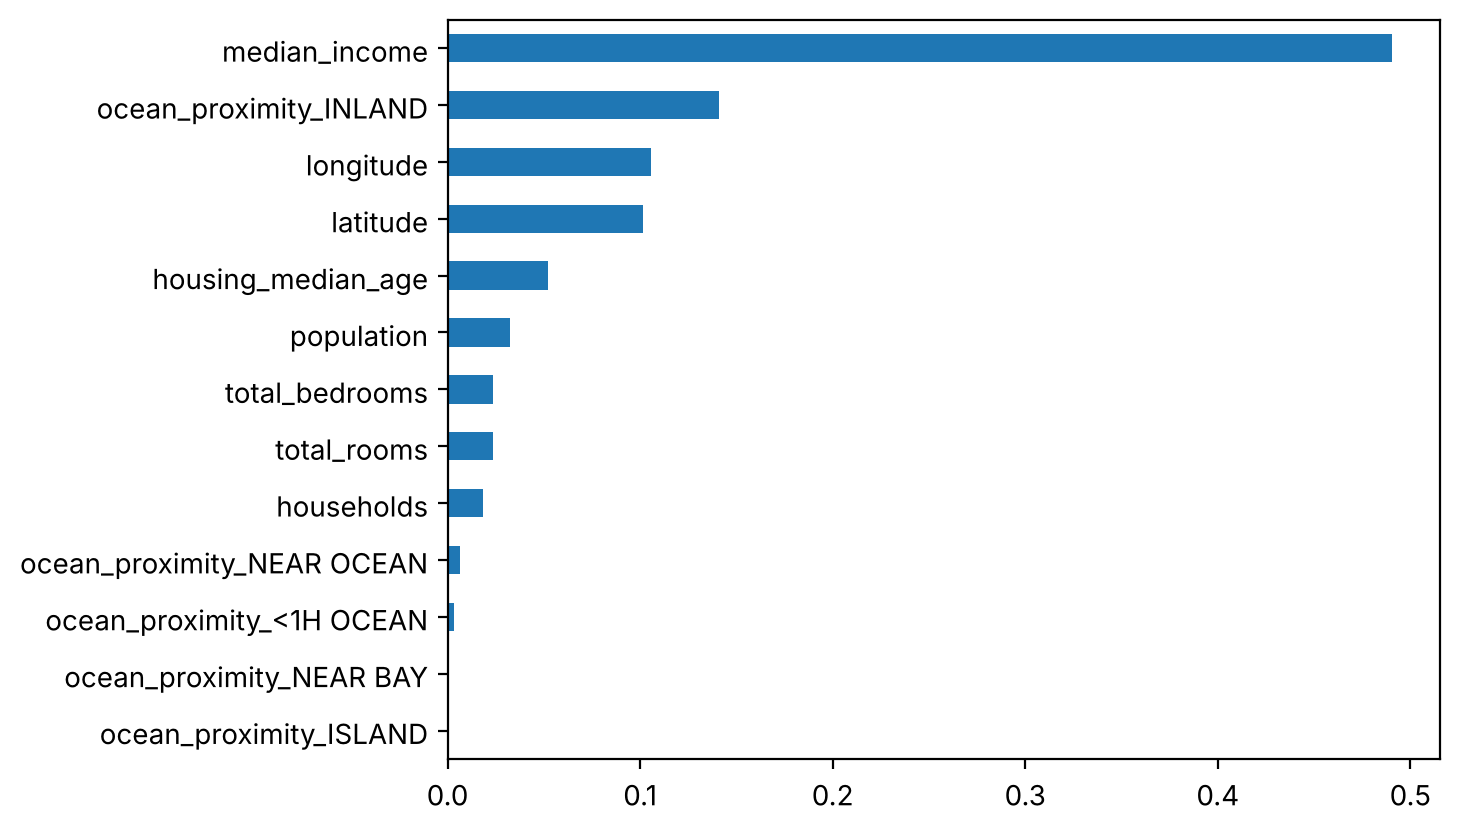

In [9]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
print('RF R2:', r2_score(y_test, rf.predict(X_test)))
pd.Series(rf.feature_importances_, index=X.columns).sort_values().plot(kind='barh')
plt.show()